# GRSprocessor validation at AAOT (AERONET-OC), Sentinel-2

Matchups of the Sentinel-2 L2A products of the **current version of GRSprocessor** (the code of this repository)
with the AERONET-OC measurements of the Acqua Alta Oceanographic Tower (**AAOT**, northern Adriatic, 45.314 N,
12.508 E, tile 32TQR). Venise is the former name of the same platform, with data until 2023-03: it can be used for
the older years (`SITE = 'Venise'`).

Steps:

1. **In situ**: AERONET-OC v3 (`aeronet_oc_db`), level 2.0 when available, else level 1.5 (flagged);
2. **Images**: the Sentinel-2 L1C acquisitions of 32TQR in the period (CDSE catalogue), with an AERONET-OC
   record within `MAX_LAG` of the overpass; local archive check and optional download (`grstbx.download`);
3. **L1C subsets**: 10.4 x 10.4 km around the platform at 20 m (`make_l1c_subsets.py`), in the archive of the
   AERONET-OC subsets (`SUBSET_DIR/<tile>/<year>/<image>.nc`, 2017-2023 already there), made once per image;
4. **Processing**: GRSprocessor on each L1C subset (`process_subset.py`, one subprocess per image, ~15-20 s and
   ~1.4 GB), one cached extraction per image and version (`CACHE/<image>.nc`, box of `EXTRACT` pixels): nothing is
   recomputed on a rerun;
5. **Matchups**: median over a `BOX` x `BOX` window at 20 m, water pixels only, homogeneity (CV) filter, nearest
   in situ record in time;
6. **Evaluation**: Rrs per band (slope, r, RMSE, bias, MdSA, SSPB, Pahlevan et al. 2020) and AOT(550), with all
   the matchups and with the Level 2.0 ones only.

Long steps (3-4) the first time: run the notebook with
`research/run_nb.sh notebook/validation/aaot_s2_matchups.ipynb 20000` (memory cap, see `CLAUDE.md`), or set
`PROCESS = False` to only evaluate what is cached.

In [1]:
import glob
import json
import os
import re
import subprocess
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

# the repository first: the grsprocessor of site-packages (3.1.1) would hide the code under test
REPO = Path.cwd().resolve().parents[1] if Path.cwd().name == 'validation' else Path.cwd().resolve()
sys.path.insert(0, str(REPO))
import grs
import GRSdriver
import aeronet_oc_db
from grstbx import download
from grstbx.matchup import matchup_metrics

assert Path(grs.__file__).resolve().is_relative_to(REPO), grs.__file__
COMMIT = subprocess.run(['git', '-C', str(REPO), 'rev-parse', '--short', 'HEAD'],
                        capture_output=True, text=True).stdout.strip()
VERSION = f'{grs.__version__}+{COMMIT}'
print('GRSprocessor', VERSION, '| GRSdriver', GRSdriver.__version__, '| aeronet_oc_db root', aeronet_oc_db.default_root())
warnings.filterwarnings('ignore', category=RuntimeWarning)

GRSprocessor 3.1.1+8d20859 | GRSdriver 2.1.1 | aeronet_oc_db root /DATA/AERONET/OCv3


## Settings

In [2]:
SITE = 'AAOT'
START, END = '2024-11-14', '2026-11-14'      # period of the images (a couple of years up to now)
MAX_LAG = pd.Timedelta(hours=1)              # in situ record to overpass (Zibordi et al. 2009: +-1 h)
SEARCH_LAG = pd.Timedelta(hours=2)           # wider lag to select the images worth processing
MAX_CLOUD = 50                               # cloud cover of the tile (%), for the selection only

L1C_DIR = '/data/satellite/s3/grstbx-s3/sentinel-2/l1c'   # <tile>/YYYY/MM/DD/<image>.SAFE
CAMS_DIR = '/data/cams/world'   # daily global files YYYY/MM/DD/YYYY-MM-DD-cams-...nc, else monthly cams_forecast_YYYY-MM.nc
CACHE = Path('/data/grs/validation/aeronet_oc') / SITE / VERSION
CACHE.mkdir(parents=True, exist_ok=True)

RESOLUTION = 20
SUBSET_DIR = '/data/satellite/Sentinel-2/subset/aeronet/L1C'   # L1C subsets <tile>/<year>/<image>.nc
HALF_SUBSET = 5200        # m: L1C subsets of 10.4 x 10.4 km (521 x 521 pixels at 20 m), as the existing archive
SUBSET_WORKERS = 4        # L1C subsets made at the same time (~3 GB each)
EXTRACT = 15              # pixels kept in the cache around the platform (15 x 15 at 20 m)
BOX = 5                   # matchup window (5 x 5 at 20 m = 100 m)
MIN_VALID = 0.5           # minimum fraction of valid water pixels in the window
MAX_CV = 0.2              # maximum coefficient of variation of Rrs(560) in the window
PLATFORM_NIR = 8e-4       # sr-1: pixels brighter than the median of the extraction at 865 nm (platform) left out

GRS_KW = {}               # other options of Process.execute, e.g. {'glint_aot': True}

PROCESS = True            # False: evaluation of the cached extractions only (no subset, no processing)
DOWNLOAD = False          # True: download the missing L1C images (CDSE S3 keys in ~/.s3cfg)

# Sentinel-2 bands (nm, GRSprocessor wl coordinate) -> AERONET-OC band (nm)
BANDS = {443: 443, 490: 490, 560: 560, 665: 667, 783: 779, 865: 865}

## 1. In situ data

In [3]:
info = aeronet_oc_db.site_info().loc[SITE]
LON, LAT, TILE = float(info.longitude), float(info.latitude), info.s2_tile
print(SITE, LAT, LON, TILE)


def insitu(site):
    """Level 2.0 records, completed by the level 1.5 ones not (yet) in level 2.0 (quality 'lev15')"""
    out = []
    for level in ['lev20', 'lev15']:
        ds = aeronet_oc_db.open_site(site, level)
        df = ds[['Rrs_Lwn', 'Rrs_Lwn_fQ', 'aot']].to_dataframe().unstack('wl')
        df.columns = [f'{v}_{int(w)}' for v, w in df.columns]
        for v in ['sza', 'wind', 'chl']:
            df[v] = ds[v].to_series()
        df['level'] = level
        out.append(df)
    lev20, lev15 = out
    df = pd.concat([lev20, lev15[~lev15.index.isin(lev20.index)]]).sort_index()
    return df


ins = insitu(SITE)
ins = ins[(ins.index >= pd.Timestamp(START) - SEARCH_LAG) & (ins.index <= pd.Timestamp(END) + SEARCH_LAG)]
print(len(ins), 'records in the period;', ins.level.value_counts().to_dict())

AAOT 45.3139 12.5083 32TQR


8341 records in the period; {'lev15': 6491, 'lev20': 1850}


Text(0.5, 1.0, 'AAOT AERONET-OC')

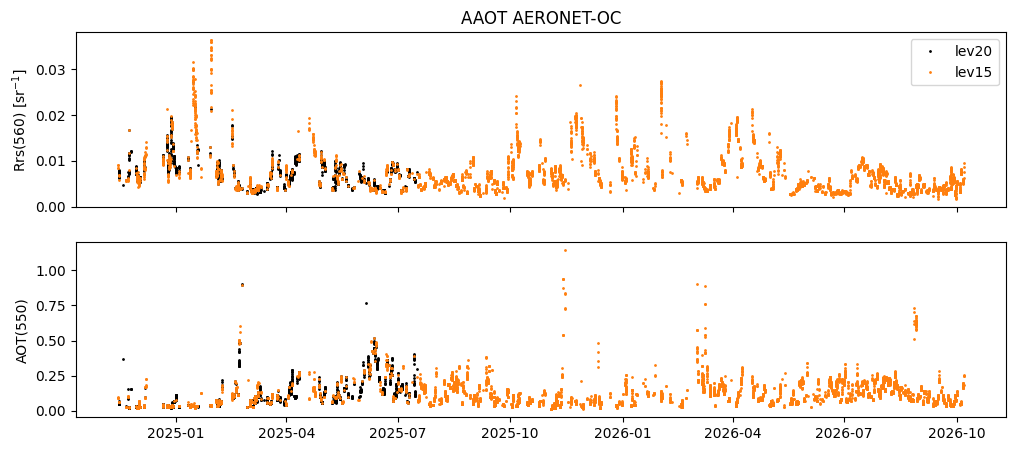

In [4]:
def aot550(df):
    """AOT at 550 nm from 490 and 667 nm (Angstrom law)"""
    a = -np.log(df['aot_667'] / df['aot_490']) / np.log(667 / 490)
    return df['aot_490'] * (550 / 490) ** -a


ins['aot_550'] = aot550(ins)
fig, ax = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
for lev, c in [('lev20', 'k'), ('lev15', 'tab:orange')]:
    s = ins[ins.level == lev]
    ax[0].plot(s.index, s.Rrs_Lwn_560, '.', ms=2, c=c, label=lev)
    ax[1].plot(s.index, s.aot_550, '.', ms=2, c=c)
ax[0].set_ylabel('Rrs(560) [sr$^{-1}$]'); ax[1].set_ylabel('AOT(550)'); ax[0].legend()
ax[0].set_title(f'{SITE} AERONET-OC')

## 2. Sentinel-2 images: catalogue, matchup candidates, local archive

In [5]:
images = download.search(TILE, START, END, level='L1C')
images['time'] = pd.to_datetime(images.time).dt.tz_localize(None)


def _key(name):
    m = re.search(r'(S2[A-D])_MSIL1C_(\d{8}T\d{6})', name)
    return m.group(1) + m.group(2)


local = {_key(os.path.basename(p)): p for p in glob.glob(f'{L1C_DIR}/{TILE}/*/*/*/*.SAFE')}
images['path'] = images.name.map(lambda n: local.get(_key(n)))     # any processing baseline
t = ins.index.values
images['n_insitu'] = [int(((t > x - SEARCH_LAG) & (t < x + SEARCH_LAG)).sum()) for x in images.time]


def cams_file(t):
    """Daily global CAMS file of the date (preferred), else the monthly global file"""
    for f in [t.strftime(f'{CAMS_DIR}/%Y/%m/%d/%Y-%m-%d-cams-global-atmospheric-composition-forecasts.nc'),
              t.strftime('/data/cams/daily/cams_forecast_%Y-%m-%d.nc'),
              t.strftime(f'{CAMS_DIR}/cams_forecast_%Y-%m.nc')]:
        if os.path.exists(f):
            return f
    return None


images['cams'] = images.time.map(cams_file)


_cams_cache = {}


def cams_covers(path, t):
    """The CAMS file exists and its forecasts cover the date (a truncated download holds only a few days)"""
    if path is None:
        return False
    if path not in _cams_cache:
        try:
            with xr.open_dataset(path) as ds:
                ft = pd.to_datetime(ds.forecast_reference_time.values)
                _cams_cache[path] = set(ft.normalize()) if ds.sizes['latitude'] > 100 else set()
        except (FileNotFoundError, OSError, AttributeError, KeyError):
            _cams_cache[path] = set()
    return t.normalize() in _cams_cache[path]


images['cams_ok'] = [cams_covers(c, t) for c, t in zip(images.cams, images.time)]

cand = images[(images.n_insitu > 0) & (images.cloud_cover <= MAX_CLOUD)].reset_index(drop=True)
print(f'{len(images)} images of {TILE} in the catalogue, {len(cand)} matchup candidates '
      f'(in situ within {SEARCH_LAG}, cloud cover <= {MAX_CLOUD} %)')
print(f'  on disk: {cand.path.notna().sum()}, missing: {cand.path.isna().sum()} '
      f'({cand[cand.path.isna()]["size"].sum() / 1e9:.0f} GB); without CAMS: {(~cand.cams_ok).sum()} '
      f'(months {sorted(set(cand.loc[~cand.cams_ok, "time"].dt.strftime("%Y-%m")))})')
cand.groupby([cand.time.dt.to_period('Q'), cand.path.notna().rename('on_disk')]).size().unstack(fill_value=0)

403 images of 32TQR in the catalogue, 210 matchup candidates (in situ within 0 days 02:00:00, cloud cover <= 50 %)
  on disk: 210, missing: 0 (0 GB); without CAMS: 8 (months ['2025-10'])


on_disk,True
time,
2024Q4,8
2025Q1,13
2025Q2,33
2025Q3,37
2025Q4,21
2026Q1,15
2026Q2,35
2026Q3,43
2026Q4,5


In [6]:
missing = cand[cand.path.isna()]
if DOWNLOAD and len(missing):
    summary = download.download(missing, L1C_DIR, storage_options=download.cdse_storage_options(), workers=4)
    print(summary)
    local = {_key(os.path.basename(p)): p for p in glob.glob(f'{L1C_DIR}/{TILE}/*/*/*/*.SAFE')}
    cand['path'] = cand.name.map(lambda n: local.get(_key(n)))
else:
    print(f'{len(missing)} images to download (DOWNLOAD = False)')

0 images to download (DOWNLOAD = False)


## 3. L1C subsets around the platform

`make_l1c_subsets.py` (current GRSdriver) cuts 521 x 521 pixels at 20 m around the platform out of each image
(angles at 60 m, bands packed in int16, ~5 MB), in `SUBSET_DIR/<tile>/<year>/<image>.nc`, the layout of the
existing AERONET-OC subsets. Made once per image (a few minutes each, `SUBSET_WORKERS` at a time); the subsets
already there are reused, also without their `.SAFE`. A failure (e.g. platform outside the swath) leaves
`<image>.nc.err`.

In [7]:
def subset_file(name):
    m = re.search(r'_MSIL1C_(\d{4})', name)
    return Path(SUBSET_DIR) / TILE / m.group(1) / name.replace('.SAFE', '.nc')


subsets = {_key(p.name): p for p in Path(SUBSET_DIR, TILE).glob('*/*.nc')}
cand['subset'] = cand.name.map(lambda n: subsets.get(_key(n)))
to_cut = cand[cand.subset.isna() & cand.path.notna()
              & ~cand.name.map(lambda n: Path(str(subset_file(n)) + '.err').exists())]
print(f'{cand.subset.notna().sum()} subsets on disk, {len(to_cut)} to make from the .SAFE')
if PROCESS and len(to_cut):
    t0 = time.time()
    r = subprocess.run([sys.executable, str(Path('make_l1c_subsets.py').resolve()), str(LON), str(LAT),
                        SUBSET_DIR, *to_cut.path, '--half', str(HALF_SUBSET), '--workers', str(SUBSET_WORKERS)],
                       capture_output=True, text=True)
    print(*[l for l in r.stdout.splitlines() if 'FAILED' in l], sep='\n')
    print(f'{(time.time() - t0) / 60:.0f} min, status {r.returncode}')
    subsets = {_key(p.name): p for p in Path(SUBSET_DIR, TILE).glob('*/*.nc')}
    cand['subset'] = cand.name.map(lambda n: subsets.get(_key(n)))
print(f'{cand.subset.notna().sum()} / {len(cand)} candidates with a subset')

209 subsets on disk, 0 to make from the .SAFE
209 / 210 candidates with a subset


## 4. GRSprocessor on the subsets

One run per L1C subset by `process_subset.py` in its own process; `EXTRACT` x `EXTRACT` pixels around the
platform are kept in `CACHE/<image>.nc` with the attributes of the run (versions, CAMS file, options). Failures
are logged in `CACHE/<image>.nc.err` and not retried (delete the file to retry); the subsets without any clear-sky
water pixel (fully cloudy) get `CACHE/<image>.nc.nowater` instead of an extraction. The images without a CAMS file
covering their date are left out (`cams_ok`).

In [8]:
WORKER = Path('process_subset.py').resolve()       # one subprocess per image: memory released between images
PY = sys.executable


def process(row):
    name = row['name'].replace('.SAFE', '')
    f = CACHE / f'{name}.nc'
    if f.exists() or Path(str(f) + '.err').exists() or Path(str(f) + '.nowater').exists():
        return f
    cmd = [PY, str(WORKER), str(row['subset']), row['cams'], str(LON), str(LAT), str(f),
           '--extract', str(EXTRACT), '--resolution', str(RESOLUTION), '--options', json.dumps(GRS_KW)]
    r = subprocess.run(cmd, capture_output=True, text=True)
    print(r.stdout.strip().splitlines()[-1] if r.stdout.strip() else f'{name}: no output (status {r.returncode})')
    if r.returncode and not Path(str(f) + '.err').exists():   # killed (memory): keep the trace
        Path(str(f) + '.err').write_text(f'status {r.returncode}\n{r.stderr[-3000:]}')
    return f


todo = cand[cand.subset.notna() & cand.cams_ok]
print(len(todo), 'images to process or already cached in', CACHE)
if PROCESS:
    t0 = time.time()
    for _, row in todo.iterrows():
        process(row)
    print(f'{(time.time() - t0) / 60:.0f} min')
for e in sorted(CACHE.glob('*.err')):
    print(e.name, '->', e.read_text().splitlines()[0])
nowater = sorted(CACHE.glob('*.nowater'))
print(len(nowater), 'images without clear-sky water pixel (cloudy):', ', '.join(e.name[:-11] for e in nowater))

201 images to process or already cached in /data/grs/validation/aeronet_oc/AAOT/3.1.1+8d20859
0 min


3 images without clear-sky water pixel (cloudy): S2A_MSIL1C_20260310T101051_N0512_R022_T32TQR_20260310T152637, S2C_MSIL1C_20250330T100051_N0511_R122_T32TQR_20250330T141746, S2C_MSIL1C_20251205T100421_N0511_R122_T32TQR_20251205T115930


## 5. Matchups

Window of `BOX` x `BOX` pixels centred on the AERONET-OC coordinates; water pixels (`mask == 0`) with a valid Rrs,
without the platform (Rrs(865) above the median of the extraction by more than `PLATFORM_NIR`). A matchup
is kept if at least `MIN_VALID` of the window is valid and the CV of Rrs(560) is below `MAX_CV` (Bailey and
Werdell 2006). The in situ record is the nearest one within `MAX_LAG`. GRSprocessor gives the directional
Rrs (no BRDF correction): it is compared with `Rrs_Lwn` (Lwn / F0, no f/Q correction); `Rrs_Lwn_fQ` is kept
for reference.

In [9]:
def window_stats(ds):
    iy, ix = ds.sizes['y'] // 2, ds.sizes['x'] // 2
    h = BOX // 2
    # the platform (~40 m north of the AERONET-OC coordinates at 20 m) is not masked: its pixels, much brighter
    # than the water in the NIR, are left out
    nir = ds.Rrs.sel(wl=865, method='nearest')
    platform = (nir - nir.median()) > PLATFORM_NIR
    w = ds.isel(y=slice(iy - h, iy + h + 1), x=slice(ix - h, ix + h + 1))
    water = ((w['mask'] == 0) if 'mask' in w else xr.ones_like(w.aot550, dtype=bool))
    water = water & ~platform.isel(y=slice(iy - h, iy + h + 1), x=slice(ix - h, ix + h + 1))
    rrs = w.Rrs.where(water & np.isfinite(w.Rrs).all('wl'))
    n = int(rrs.isel(wl=0).count())
    r560 = rrs.sel(wl=560, method='nearest')
    out = {'n_valid': n, 'frac_valid': n / BOX ** 2,
           'cv560': float(r560.std() / r560.mean()) if n > 1 else np.nan,
           'aot550_sat': float(w.aot550.where(water).median()),
           'BRDFg': float(w.BRDFg.where(water).median()) if 'BRDFg' in w else np.nan,
           'wind_sat': float(w.wind.median()) if 'wind' in w else np.nan,
           'sza_sat': float(w.sza.median()) if 'sza' in w else np.nan}
    for wl_s in BANDS:
        out[f'Rrs_sat_{wl_s}'] = float(rrs.sel(wl=wl_s, method='nearest').median())
        out[f'Rrs_sat_std_{wl_s}'] = float(rrs.sel(wl=wl_s, method='nearest').std())
    return out


rows = []
for f in sorted(CACHE.glob('*.nc')):
    with xr.open_dataset(f) as ds:
        r = window_stats(ds)
        r.update(image=ds.attrs['image'],
                 time=pd.to_datetime(re.search(r'_MSIL1C_(\d{8}T\d{6})', ds.attrs['image']).group(1)))
    rows.append(r)
sat = pd.DataFrame(rows, columns=list(rows[0]) if rows else ['image', 'time'])
sat = sat[(sat.time >= pd.Timestamp(START)) & (sat.time <= pd.Timestamp(END) + pd.Timedelta(days=1))].reset_index(drop=True)
print(len(sat), 'cached extractions in the period;', len(list(CACHE.glob('*.err'))), 'failures')
if sat.empty:
    raise SystemExit('no cached extraction yet: download the images / CAMS months and run section 3')

# nearest in situ record within MAX_LAG
idx = ins.index.get_indexer(sat.time, method='nearest')
mu = pd.concat([sat, ins.iloc[idx].reset_index().rename(columns={'time': 'time_insitu'})], axis=1)
mu['lag_min'] = (mu.time_insitu - mu.time).dt.total_seconds() / 60
mu['ok'] = (mu.lag_min.abs() <= MAX_LAG.total_seconds() / 60) & (mu.frac_valid >= MIN_VALID) & (mu.cv560 <= MAX_CV)
print(f"{mu.ok.sum()} valid matchups ({(mu.ok & (mu.level == 'lev20')).sum()} with level 2.0)")
mu.to_csv(CACHE / f'matchups_{SITE}.csv', index=False)
mu.loc[mu.ok, ['image', 'lag_min', 'level', 'n_valid', 'cv560', 'aot550_sat', 'aot_550', 'BRDFg', 'wind_sat']].round(4)

198 cached extractions in the period; 0 failures
145 valid matchups (30 with level 2.0)


,image,lag_min,level,n_valid,cv560,aot550_sat,aot_550,BRDFg,wind_sat
1,S2A_MSIL1C_20241130T100351_N0511_R122_T32TQR_2...,12.2833,lev20,23,0.1093,0.0257,0.0258,0.0013,4.9074
2,S2A_MSIL1C_20241230T100421_N0511_R122_T32TQR_2...,25.4833,lev20,18,0.0393,0.1025,0.0698,-0.0000,1.4004
3,S2A_MSIL1C_20250112T101401_N0511_R022_T32TQR_2...,-12.2000,lev20,21,0.0625,0.0370,0.0298,0.0015,4.4945
4,S2A_MSIL1C_20250404T101041_N0511_R022_T32TQR_2...,-10.6833,lev20,22,0.0776,0.2308,0.1728,0.0005,1.4351
5,S2A_MSIL1C_20250411T100041_N0511_R122_T32TQR_2...,2.2167,lev15,23,0.0397,0.2285,0.2591,0.0036,1.6428
...,...,...,...,...,...,...,...,...,...
193,S2C_MSIL1C_20260904T100551_N0512_R022_T32TQR_2...,-10.1333,lev15,23,0.1361,0.1224,0.1313,0.0044,1.5081
194,S2C_MSIL1C_20260911T100021_N0512_R122_T32TQR_2...,-16.1000,lev15,25,0.1915,0.0408,0.0823,0.0039,2.4766
195,S2C_MSIL1C_20260914T100631_N0512_R022_T32TQR_2...,-13.8500,lev15,23,0.1561,0.0734,0.0688,0.0030,1.4175
196,S2C_MSIL1C_20261001T100031_N0513_R122_T32TQR_2...,-14.4333,lev15,25,0.1573,0.1387,0.1122,0.0021,2.7992


## 6. Evaluation

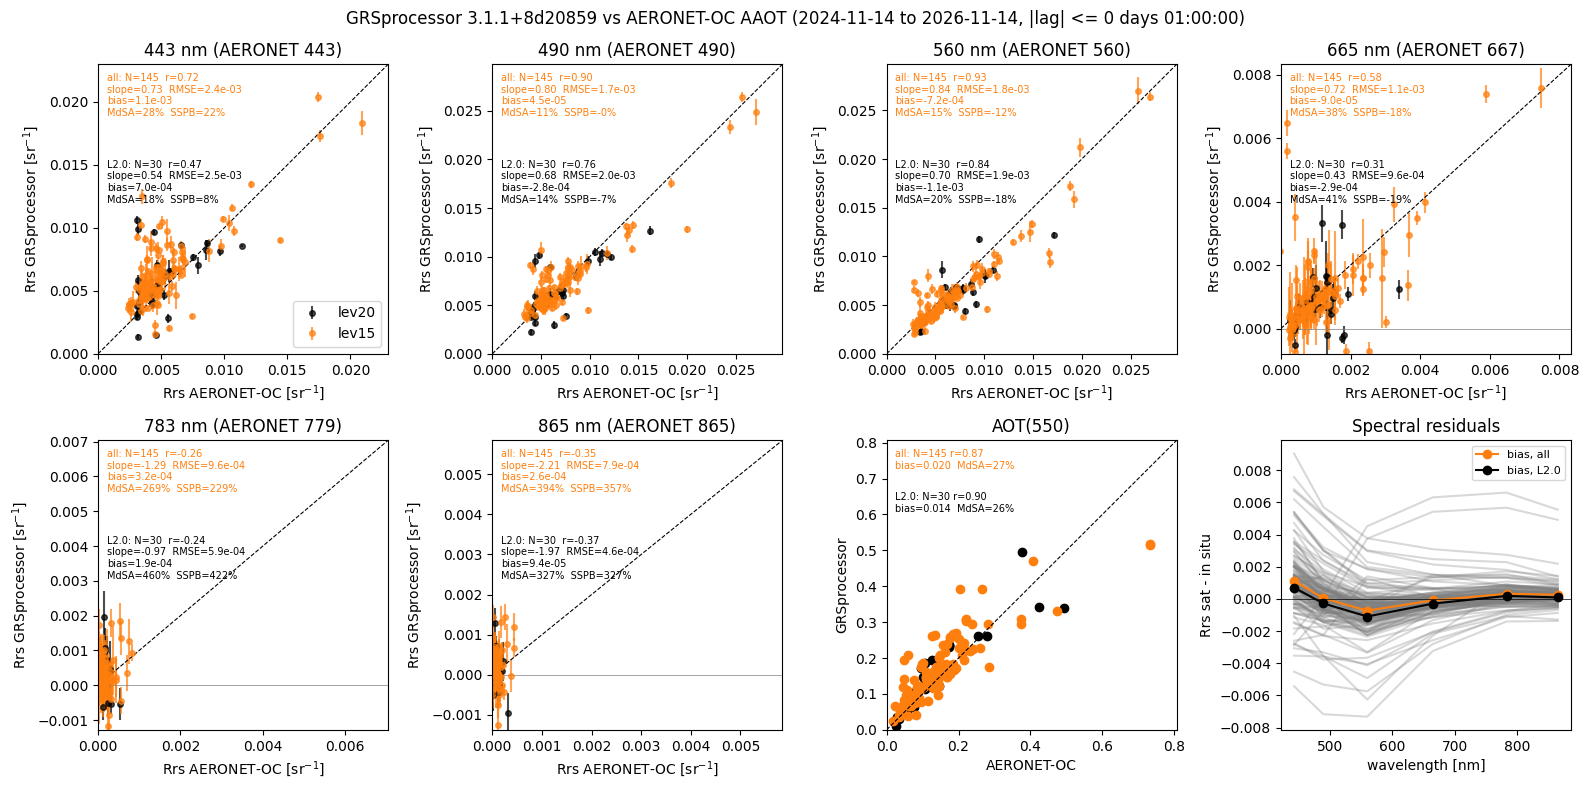

In [10]:
ok = mu[mu.ok]
if ok.empty:
    raise SystemExit('no valid matchup')
ok20 = ok[ok.level == 'lev20']          # Level 2.0 only (quality-assured in situ data)
stats, stats20 = {}, {}
fig, axs = plt.subplots(2, 4, figsize=(16, 8))
for ax, (wl_s, wl_a) in zip(axs.flat, BANDS.items()):
    x, y = ok[f'Rrs_Lwn_{wl_a}'], ok[f'Rrs_sat_{wl_s}']
    stats[wl_s] = matchup_metrics(x, y)
    stats20[wl_s] = matchup_metrics(ok20[f'Rrs_Lwn_{wl_a}'], ok20[f'Rrs_sat_{wl_s}'])
    vmax = np.nanmax([x.max(), y.max()]) * 1.1
    for lev, c in [('lev20', 'k'), ('lev15', 'tab:orange')]:
        s = ok.level == lev
        ax.errorbar(x[s], y[s], yerr=ok.loc[s, f'Rrs_sat_std_{wl_s}'], fmt='o', ms=4, c=c, alpha=.7, label=lev)
    ax.plot([0, vmax], [0, vmax], 'k--', lw=.8)
    ax.axhline(0, c='grey', lw=.5)
    ax.set(xlim=(0, vmax), ylim=(min(0, np.nanmin(y) * 1.1), vmax), title=f'{wl_s} nm (AERONET {wl_a})',
           xlabel='Rrs AERONET-OC [sr$^{-1}$]', ylabel='Rrs GRSprocessor [sr$^{-1}$]')
    for k, (lab, m) in enumerate([('all', stats[wl_s]), ('L2.0', stats20[wl_s])]):
        ax.text(.03, .97 - .3 * k, f"{lab}: N={m['N']}  r={m['r']:.2f}\nslope={m['slope']:.2f}  RMSE={m['rmse']:.1e}\n"
                f"bias={m['bias']:.1e}\nMdSA={m['eps']:.0f}%  SSPB={m['beta']:.0f}%",
                transform=ax.transAxes, va='top', fontsize=7, color='k' if k else 'tab:orange')
axs.flat[0].legend(loc='lower right')

ax = axs.flat[len(BANDS)]
x, y = ok.aot_550, ok.aot550_sat
stats['aot550'] = matchup_metrics(x, y)
stats20['aot550'] = matchup_metrics(ok20.aot_550, ok20.aot550_sat)
for lev, c in [('lev20', 'k'), ('lev15', 'tab:orange')]:
    ax.plot(x[ok.level == lev], y[ok.level == lev], 'o', c=c); vmax = np.nanmax([x.max(), y.max()]) * 1.1
ax.plot([0, vmax], [0, vmax], 'k--', lw=.8)
ax.set(xlim=(0, vmax), ylim=(0, vmax), title='AOT(550)', xlabel='AERONET-OC', ylabel='GRSprocessor')
for k, (lab, m) in enumerate([('all', stats['aot550']), ('L2.0', stats20['aot550'])]):
    ax.text(.03, .97 - .15 * k, f"{lab}: N={m['N']} r={m['r']:.2f}\nbias={m['bias']:.3f}  MdSA={m['eps']:.0f}%",
            transform=ax.transAxes, va='top', fontsize=7, color='k' if k else 'tab:orange')

ax = axs.flat[-1]
wls = list(BANDS)
for _, r in ok.iterrows():
    ax.plot(wls, [r[f'Rrs_sat_{w}'] - r[f'Rrs_Lwn_{BANDS[w]}'] for w in wls], c='grey', alpha=.3)
ax.plot(wls, [stats[w]['bias'] for w in wls], 'o-', c='tab:orange', label='bias, all')
ax.plot(wls, [stats20[w]['bias'] for w in wls], 'ko-', label='bias, L2.0')
ax.legend(fontsize=8)
ax.axhline(0, c='k', lw=.5); ax.set(xlabel='wavelength [nm]', ylabel='Rrs sat - in situ', title='Spectral residuals')
fig.suptitle(f'GRSprocessor {VERSION} vs AERONET-OC {SITE} ({START} to {END}, |lag| <= {MAX_LAG})')
fig.tight_layout()
fig.savefig(CACHE / f'matchups_{SITE}.png', dpi=150)

In [11]:
# statistics with all the matchups (levels 2.0 and 1.5) and with the level 2.0 ones only
table = pd.concat({'all': pd.DataFrame(stats).T, 'lev20': pd.DataFrame(stats20).T}, names=['insitu', 'band'])
table.to_csv(CACHE / f'metrics_{SITE}.csv')
table.round({'slope': 3, 'intercept': 5, 'r': 3, 'rmse': 5, 'bias': 5, 'mape': 1, 'eps': 1, 'beta': 1})

N  slope  intercept      r     rmse     bias    mape  \
insitu band                                                               
all    443     145.0  0.735    0.00254  0.723  0.00239  0.00113    40.1   
       490     145.0  0.802    0.00145  0.899  0.00173  0.00004    18.1   
       560     145.0  0.835    0.00043  0.926  0.00175 -0.00072    18.7   
       665     145.0  0.723    0.00024  0.584  0.00109 -0.00009   152.3   
       783     145.0 -1.291    0.00062 -0.261  0.00096  0.00032  1040.1   
       865     145.0 -2.212    0.00045 -0.354  0.00079  0.00026  2083.2   
       aot550  145.0  0.760    0.05453  0.869  0.05957  0.01965    35.7   
lev20  443      30.0  0.537    0.00309  0.475  0.00249  0.00070    40.3   
       490      30.0  0.682    0.00197  0.763  0.00203 -0.00028    22.9   
       560      30.0  0.699    0.00101  0.840  0.00192 -0.00109    20.1   
       665      30.0  0.428    0.00035  0.310  0.00096 -0.00029    57.9   
       783      30.0 -0.973    0.00042 -0.243  0.00059  0.00019   906.9   
       865      30.0 -1.972    0.00030 -0.366  0.00046  0.00009  4432.8   
       aot550   30.0  0.859    0.03432  0.901  0.05248  0.01423    27.1   

                 eps   beta  
insitu band                  
all    443      27.6   21.8  
       490      11.4   -0.2  
       560      15.2  -12.3  
       665      37.8  -17.8  
       783     268.7  229.4  
       865     394.3  357.2  
       aot550   27.0   20.3  
lev20  443      17.7    8.5  
       490      13.7   -7.4  
       560      20.3  -18.3  
       665      41.2  -18.9  
       783     459.9  422.4  
       865     327.1  327.1  
       aot550   25.7    8.7

### Residuals against the conditions of the scene

Error of Rrs(865) and of the AOT against the sunglint (`BRDFg`), the wind and the sun zenith angle: the
over-estimated AOT under glint (see `research/03_aot_overestimation.ipynb`) shows here as a negative
Rrs(865) residual growing with `BRDFg`.

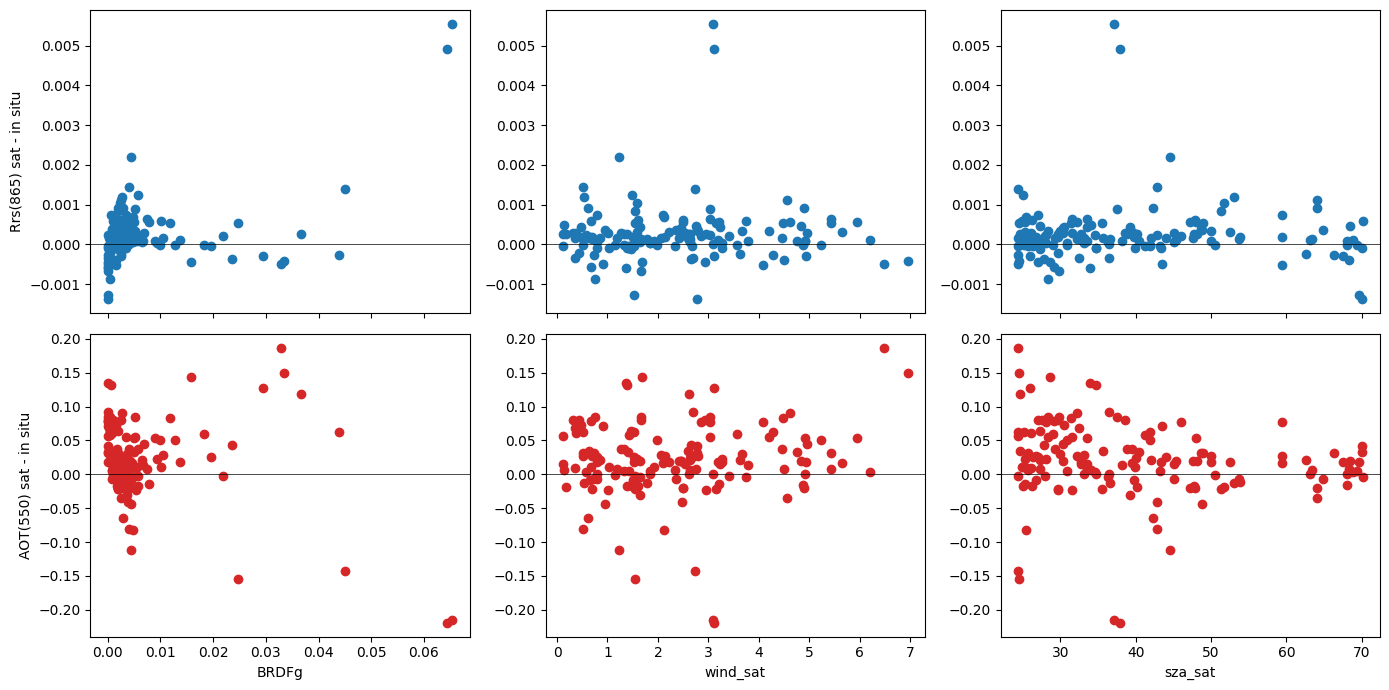

In [12]:
fig, axs = plt.subplots(2, 3, figsize=(14, 7), sharex='col')
res865 = ok.Rrs_sat_865 - ok.Rrs_Lwn_865
resaot = ok.aot550_sat - ok.aot_550
for j, v in enumerate(['BRDFg', 'wind_sat', 'sza_sat']):
    axs[0, j].plot(ok[v], res865, 'o'); axs[0, j].axhline(0, c='k', lw=.5)
    axs[1, j].plot(ok[v], resaot, 'o', c='tab:red'); axs[1, j].axhline(0, c='k', lw=.5)
    axs[1, j].set_xlabel(v)
axs[0, 0].set_ylabel('Rrs(865) sat - in situ'); axs[1, 0].set_ylabel('AOT(550) sat - in situ')
fig.tight_layout()